# UCS420 Lab Assignment 10 — NLP using Python-II
**Roll No.:** 1024160094  
**Name:** Pragun

In [1]:
ROLL_NO = 1024160094
NAME = "Pragun"

import re, nltk
from collections import Counter
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from IPython.display import display

for item in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(item, quiet=True)

stop_words = set(stopwords.words("english"))
print(ROLL_NO, NAME)

1024160094 Pragun


---
## Q1. Text Preprocessing
- Write a paragraph (5–6 sentences).
- Lowercase, remove punctuation and tokenize.
- Compare `split()` and `word_tokenize()`.
- Remove stopwords and find word frequency.

In [2]:
paragraph = ("Cricket is my favorite sport because every match feels different. "
             "I enjoy watching close games with my friends. "
             "Good players stay calm even when their team is losing. "
             "Batters practice timing, while bowlers keep trying new deliveries. "
             "The final overs are often exciting and full of surprises. "
             "Playing cricket on weekends also helps me relax after classes.")

clean = re.sub(r"[^a-z\s]", "", paragraph.lower())
words = word_tokenize(clean)
filtered = [w for w in words if w not in stop_words]

print("Clean text:", clean)
print("Sentences:", sent_tokenize(paragraph))
print("Words:", words)
print("split():", paragraph.split())
print("word_tokenize():", word_tokenize(paragraph))
print("Without stopwords:", filtered)
print("Word frequency:", Counter(filtered))

Clean text: cricket is my favorite sport because every match feels different i enjoy watching close games with my friends good players stay calm even when their team is losing batters practice timing while bowlers keep trying new deliveries the final overs are often exciting and full of surprises playing cricket on weekends also helps me relax after classes
Sentences: ['Cricket is my favorite sport because every match feels different.', 'I enjoy watching close games with my friends.', 'Good players stay calm even when their team is losing.', 'Batters practice timing, while bowlers keep trying new deliveries.', 'The final overs are often exciting and full of surprises.', 'Playing cricket on weekends also helps me relax after classes.']
Words: ['cricket', 'is', 'my', 'favorite', 'sport', 'because', 'every', 'match', 'feels', 'different', 'i', 'enjoy', 'watching', 'close', 'games', 'with', 'my', 'friends', 'good', 'players', 'stay', 'calm', 'even', 'when', 'their', 'team', 'is', 'losing',

**Observation:**
- `split()` separates at spaces; `word_tokenize()` also separates punctuation.
- Removing stopwords leaves the main words.

---
## Q2. Stemming and Lemmatization
- Use the paragraph from Q1.
- Extract alphabetic words and remove stopwords.
- Compare Porter stemming and WordNet lemmatization.

In [3]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
import pandas as pd

all_words = re.findall(r"[a-z]+", paragraph.lower())
words = [w for w in all_words if w not in stop_words]
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

print("Alphabetic words:", all_words)
print("Without stopwords:", words)
display(pd.DataFrame({
    "Word": words,
    "Stem": [stemmer.stem(w) for w in words],
    "Lemma": [lemmatizer.lemmatize(w) for w in words]
}))

Alphabetic words: ['cricket', 'is', 'my', 'favorite', 'sport', 'because', 'every', 'match', 'feels', 'different', 'i', 'enjoy', 'watching', 'close', 'games', 'with', 'my', 'friends', 'good', 'players', 'stay', 'calm', 'even', 'when', 'their', 'team', 'is', 'losing', 'batters', 'practice', 'timing', 'while', 'bowlers', 'keep', 'trying', 'new', 'deliveries', 'the', 'final', 'overs', 'are', 'often', 'exciting', 'and', 'full', 'of', 'surprises', 'playing', 'cricket', 'on', 'weekends', 'also', 'helps', 'me', 'relax', 'after', 'classes']
Without stopwords: ['cricket', 'favorite', 'sport', 'every', 'match', 'feels', 'different', 'enjoy', 'watching', 'close', 'games', 'friends', 'good', 'players', 'stay', 'calm', 'even', 'team', 'losing', 'batters', 'practice', 'timing', 'bowlers', 'keep', 'trying', 'new', 'deliveries', 'final', 'overs', 'often', 'exciting', 'full', 'surprises', 'playing', 'cricket', 'weekends', 'also', 'helps', 'relax', 'classes']


,Word,Stem,Lemma
0,cricket,cricket,cricket
1,favorite,favorit,favorite
2,sport,sport,sport
3,every,everi,every
4,match,match,match
5,feels,feel,feel
6,different,differ,different
7,enjoy,enjoy,enjoy
8,watching,watch,watching
9,close,close,close


**Observation:**
- Stemming is faster but may shorten words too much.
- Lemmatization gives proper dictionary forms more often.

---
## Q3. Bag of Words and TF-IDF
- Choose three short texts.
- Find Bag of Words and TF-IDF scores.
- Show the top three words for each text.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The phone has a good camera and a bright screen.",
    "The laptop has a fast processor and long battery life.",
    "The headphones offer clear sound and great noise cancellation."
]

bow = CountVectorizer(stop_words="english")
tfidf = TfidfVectorizer(stop_words="english")
print("Bag of Words:")
display(pd.DataFrame(bow.fit_transform(texts).toarray(), columns=bow.get_feature_names_out()))

scores = tfidf.fit_transform(texts).toarray()
terms = tfidf.get_feature_names_out()
print("TF-IDF scores:")
display(pd.DataFrame(scores.round(2), columns=terms))
for i, row in enumerate(scores, 1):
    top = row.argsort()[-3:][::-1]
    print(f"Text {i} top words:", list(terms[top]))

Bag of Words:


,battery,bright,camera,cancellation,clear,fast,good,great,headphones,laptop,life,long,noise,offer,phone,processor,screen,sound
0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0
1,1,0,0,0,0,1,0,0,0,1,1,1,0,0,0,1,0,0
2,0,0,0,1,1,0,0,1,1,0,0,0,1,1,0,0,0,1


TF-IDF scores:


,battery,bright,camera,cancellation,clear,fast,good,great,headphones,laptop,life,long,noise,offer,phone,processor,screen,sound
0,0.00,0.45,0.45,0.00,0.00,0.00,0.45,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.45,0.00,0.45,0.00
1,0.41,0.00,0.00,0.00,0.00,0.41,0.00,0.00,0.00,0.41,0.41,0.41,0.00,0.00,0.00,0.41,0.00,0.00
2,0.00,0.00,0.00,0.38,0.38,0.00,0.00,0.38,0.38,0.00,0.00,0.00,0.38,0.38,0.00,0.00,0.00,0.38


Text 1 top words: ['screen', 'phone', 'camera']
Text 2 top words: ['laptop', 'processor', 'battery']
Text 3 top words: ['sound', 'noise', 'clear']


**Observation:**
- TF-IDF gives higher importance to words that describe each text.
- Common words have less importance.

---
## Q4. Text Similarity
- Write two technology texts (4 lines each).
- Preprocess them and calculate Jaccard and cosine similarity.
- Compare the results.

In [5]:
from sklearn.metrics.pairwise import cosine_similarity

ai = """AI learns from data.
It finds patterns in examples.
Models can predict future outcomes.
Developers test the results carefully."""

blockchain = """Blockchain stores records in blocks.
It shares data across computers.
Networks verify each transaction.
Developers test the system carefully."""

a = [w for w in re.findall(r"[a-z]+", ai.lower()) if w not in stop_words]
b = [w for w in re.findall(r"[a-z]+", blockchain.lower()) if w not in stop_words]
A, B = set(a), set(b)
jaccard = len(A & B) / len(A | B)

vectors = TfidfVectorizer(stop_words="english").fit_transform([ai, blockchain])
cosine = cosine_similarity(vectors[0], vectors[1])[0][0]

print("AI tokens:", a)
print("Blockchain tokens:", b)
print("Jaccard similarity:", round(jaccard, 3))
print("Cosine similarity:", round(cosine, 3))

AI tokens: ['ai', 'learns', 'data', 'finds', 'patterns', 'examples', 'models', 'predict', 'future', 'outcomes', 'developers', 'test', 'results', 'carefully']
Blockchain tokens: ['blockchain', 'stores', 'records', 'blocks', 'shares', 'data', 'across', 'computers', 'networks', 'verify', 'transaction', 'developers', 'test', 'system', 'carefully']
Jaccard similarity: 0.16
Cosine similarity: 0.176


**Observation:**
- Jaccard compares shared words.
- Cosine similarity is more useful here because it uses TF-IDF weights.

---
## Q5. Sentiment Analysis
- Write short product reviews.
- Find polarity, subjectivity and sentiment.
- Make a word cloud using positive reviews.

Review | Polarity | Subjectivity | Sentiment
The headphones sound great and feel comfortable. | 0.53 0.65 | Positive
I love the clear audio and long battery life. | 0.18 0.46 | Positive
The headphones came with a charging cable. | 0.0 0.0 | Neutral
The sound is poor and the battery is terrible. | -0.33 0.67 | Negative


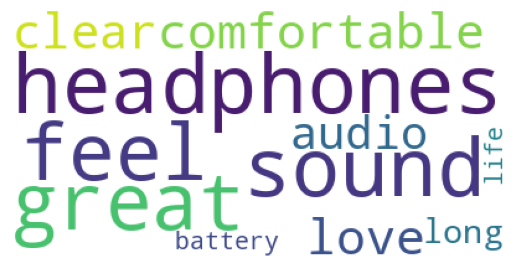

In [6]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "The headphones sound great and feel comfortable.",
    "I love the clear audio and long battery life.",
    "The headphones came with a charging cable.",
    "The sound is poor and the battery is terrible."
]

positive = []
print("Review | Polarity | Subjectivity | Sentiment")
for review in reviews:
    p, s = TextBlob(review).sentiment
    label = "Positive" if p > 0 else "Negative" if p < 0 else "Neutral"
    print(review, "|", round(p, 2), round(s, 2), "|", label)
    if label == "Positive":
        positive.append(review)

cloud = WordCloud(background_color="white").generate(" ".join(positive))
plt.imshow(cloud)
plt.axis("off")
plt.show()

**Observation:**
- Polarity shows positive or negative feeling.
- Subjectivity shows how opinion-based the review is.
- The word cloud uses only positive reviews.

---
## Q6. Text Generation
- Use a paragraph of about 100 words.
- Tokenize it and create training sequences.
- Train a small Dense model and generate three lines.

In [7]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences

text = ("Learning to code takes patience and practice. Every day I try to understand "
        "a small idea instead of rushing through lessons. A good project starts "
        "with a simple problem and a clear plan. Students learn better when they "
        "build things and fix their mistakes. When my code fails I read the error "
        "and test one step at a time. Working with friends also helps because we "
        "can share ideas and find bugs faster. I enjoy seeing a program finally "
        "work after many attempts. Small improvements give me confidence and make "
        "the next challenge easier. Coding is a skill that grows with regular practice.")

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
ids = tokenizer.texts_to_sequences([text])[0]
sequences = [ids[i:i+3] for i in range(len(ids)-2)]
X, y = np.array(sequences)[:, :2], np.array(sequences)[:, 2]

model = Sequential([Input(shape=(2,)), Embedding(len(tokenizer.word_index)+1, 16),
                    Flatten(), Dense(32, activation="relu"),
                    Dense(len(tokenizer.word_index)+1, activation="softmax")])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
model.fit(X, y, epochs=60, verbose=0)

def generate(seed):
    line = seed
    for _ in range(8):
        tokens = tokenizer.texts_to_sequences([line])[0][-2:]
        x = pad_sequences([tokens], maxlen=2)
        word_id = np.argmax(model.predict(x, verbose=0)[0][1:]) + 1
        line += " " + tokenizer.index_word[word_id]
    return line

for seed in ["learning to", "a good", "students learn"]:
    print(generate(seed))

learning to a and and practice and and practice and
a good i and and practice and and practice and
students learn a and and practice and and practice and


**Observation:**
- The model learns to predict the next word.
- With only 100 words of training, some generated lines may repeat.